Saving Y77.jpg to Y77.jpg


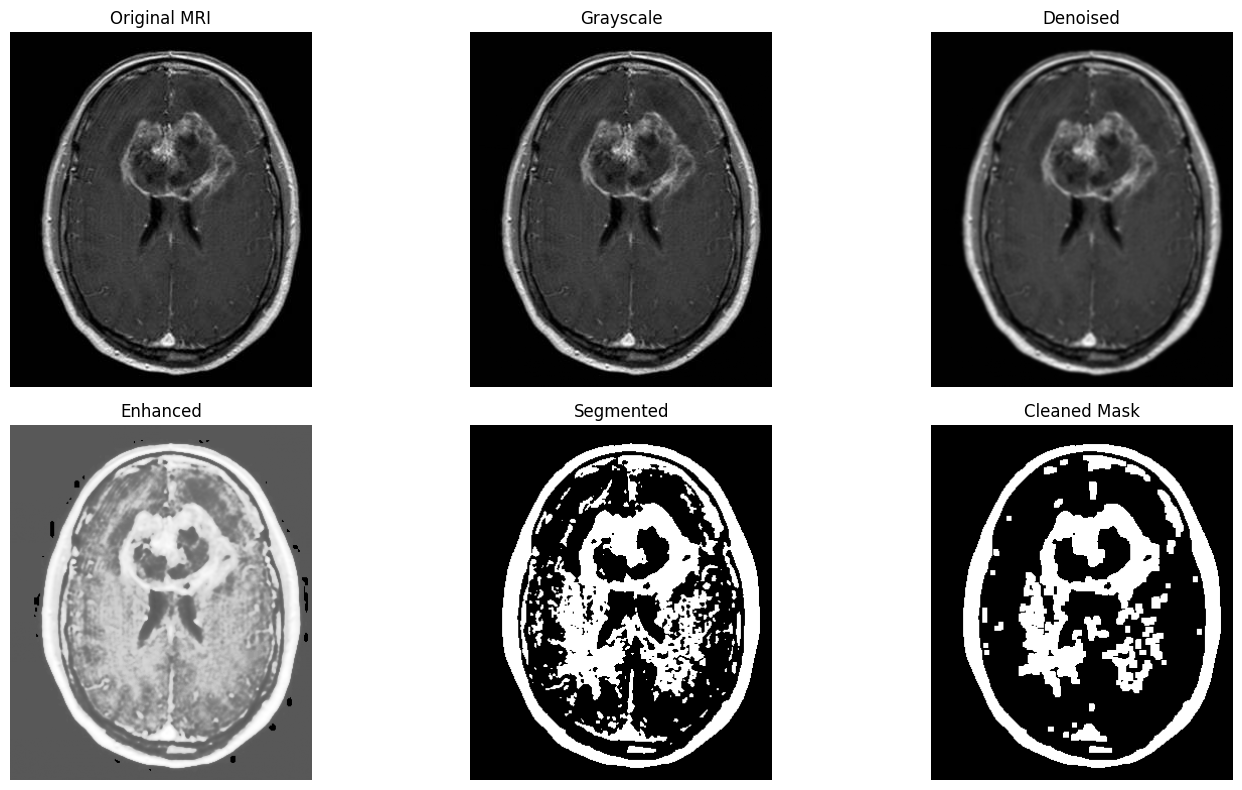

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload one single MRI scan
uploaded_img = files.upload()
image_name = next(iter(uploaded_img))

# Load image without depending on its filename
img = cv2.imdecode(
    np.frombuffer(uploaded_img[image_name], dtype=np.uint8),
    cv2.IMREAD_COLOR
)

if img is None:
    raise ValueError("Image load nahi hui. Dobara image upload karo.")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 1. Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

# 2. Noise removal
denoised = cv2.GaussianBlur(gray, (5, 5), 0)

# 3. Contrast enhancement
enhanced = cv2.equalizeHist(denoised)

# 4. Thresholding
_, segmented = cv2.threshold(
    enhanced, 180, 255, cv2.THRESH_BINARY
)

# 5. Morphological opening
kernel = np.ones((5, 5), np.uint8)
cleaned = cv2.morphologyEx(
    segmented, cv2.MORPH_OPEN, kernel
)

# Display all six outputs
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(denoised, cmap="gray")
plt.title("Denoised")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(enhanced, cmap="gray")
plt.title("Enhanced")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(segmented, cmap="gray")
plt.title("Segmented")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(cleaned, cmap="gray")
plt.title("Cleaned Mask")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
from google.colab import files

uploaded_zip = files.upload()

Saving MRI.zip to MRI.zip


In [ ]:

import zipfile
import os

zip_path = "/content/MRI.zip"
extract_path = "/content/brain_data"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")
print("Top-level folders:", os.listdir(extract_path))


Dataset extracted successfully!
Top-level folders: ['yes', 'no', 'brain_tumor_dataset']


In [ ]:

import os

for root, dirs, files in os.walk("/content/brain_data"):
    if "yes" in dirs and "no" in dirs:
        data_dir = root
        break
else:
    raise FileNotFoundError(
        "yes/no folders nahi mile. Folder structure check karo."
    )

print("Dataset folder:", data_dir)
print("Tumor images:", len(os.listdir(os.path.join(data_dir, "yes"))))
print("No-tumor images:", len(os.listdir(os.path.join(data_dir, "no"))))


Dataset folder: /content/brain_data
Tumor images: 155
No-tumor images: 98


In [ ]:

import os

data_dir = "/content/brain_data/brain_tumor_dataset"

print("Using dataset folder:", data_dir)
print("Classes found:", os.listdir(data_dir))

assert set(os.listdir(data_dir)) == {"yes", "no"}, \
    "Folder structure check karo!"


Using dataset folder: /content/brain_data/brain_tumor_dataset
Classes found: ['yes', 'no']


In [ ]:

import tensorflow as tf

img_size = (150, 150)
batch_size = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary"
)

class_names = train_ds.class_names
print("Classes:", class_names)


Found 253 files belonging to 2 classes.
Using 203 files for training.
Found 253 files belonging to 2 classes.
Using 50 files for validation.
Classes: ['no', 'yes']


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(150, 150, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [ ]:

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 34, 34, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │     1,183,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,240,193 (4.73 MB)

 Trainable params: 1,240,193 (4.73 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)


Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 596ms/step - accuracy: 0.6650 - loss: 0.6406 - val_accuracy: 0.7600 - val_loss: 0.5234
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 706ms/step - accuracy: 0.7586 - loss: 0.5218 - val_accuracy: 0.7600 - val_loss: 0.5265
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 752ms/step - accuracy: 0.7882 - loss: 0.5093 - val_accuracy: 0.7600 - val_loss: 0.5153
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 569ms/step - accuracy: 0.8276 - loss: 0.4454 - val_accuracy: 0.8000 - val_loss: 0.5209
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 588ms/step - accuracy: 0.8276 - loss: 0.3967 - val_accuracy: 0.7600 - val_loss: 0.4990
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 715ms/step - accuracy: 0.8374 - loss: 0.3714 - val_accuracy: 0.8200 - val_loss: 0.4445
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 713ms/step - accuracy: 0.8867 - loss: 0.3087 - val_accuracy: 0.8000 - val_loss: 0.4671
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 576ms/step - accuracy: 0.8966 - loss: 0.2695 - val_accura

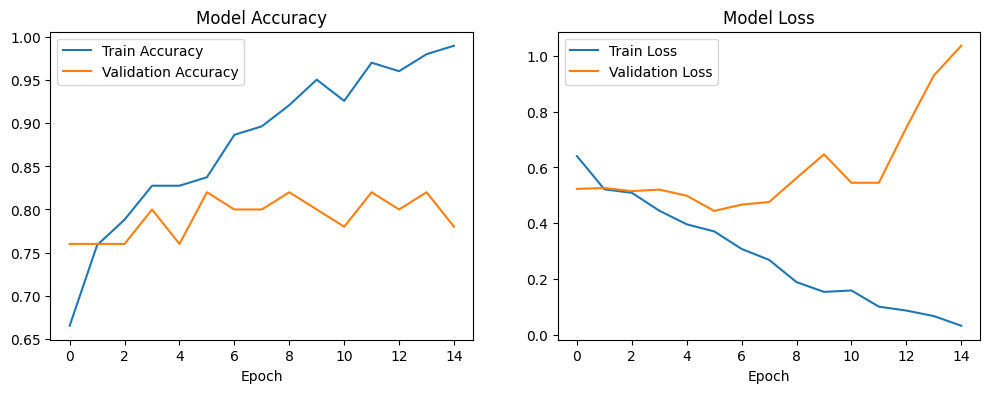

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.legend()

plt.show()


In [ ]:

model.save('/content/brain_tumor_model.h5')

print("Model saved successfully!")


Model saved successfully!


In [ ]:
from google.colab import files
files.download('/content/brain_tumor_model.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Testing image: /content/brain_data/brain_tumor_dataset/yes/Y1.jpg
Predicted probability: 0.999972939491272
Result: Tumor Detected


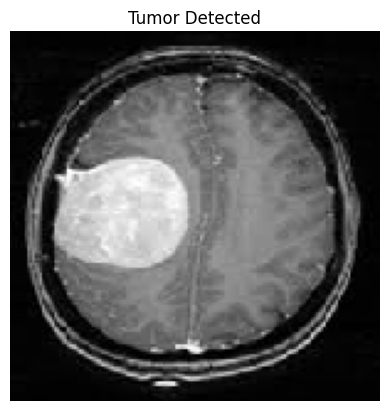

In [ ]:

import os
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

yes_file = sorted(os.listdir(data_dir + '/yes'))[0]
img_path = data_dir + '/yes/' + yes_file

img = image.load_img(img_path, target_size=(150, 150))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

result = (
    "Tumor Detected"
    if prediction[0][0] > 0.5
    else "No Tumor Detected"
)

print("Testing image:", img_path)
print("Predicted probability:", float(prediction[0][0]))
print("Result:", result)

plt.imshow(img)
plt.axis('off')
plt.title(result)
plt.show()


Testing image: /content/brain_data/brain_tumor_dataset/no/1 no.jpeg
Predicted probability: 6.969568494241685e-05
Result: No Tumor Detected


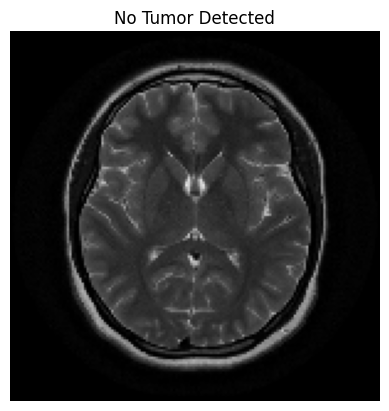

In [ ]:

no_file = sorted(os.listdir(data_dir + '/no'))[0]
img_path2 = data_dir + '/no/' + no_file

img2 = image.load_img(img_path2, target_size=(150, 150))
img_array2 = image.img_to_array(img2)
img_array2 = np.expand_dims(img_array2, axis=0)

prediction2 = model.predict(img_array2, verbose=0)

result2 = (
    "Tumor Detected"
    if prediction2[0][0] > 0.5
    else "No Tumor Detected"
)

print("Testing image:", img_path2)
print("Predicted probability:", float(prediction2[0][0]))
print("Result:", result2)

plt.imshow(img2)
plt.axis('off')
plt.title(result2)
plt.show()
